In [59]:
%pip install seaborn
%pip install scipy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from scipy.stats import spearmanr


print("Everything is working!")

Everything is working!


In [42]:
from pathlib import Path

print("Current folder:", Path.cwd())

print("\nCSV files found:")
for file in Path.cwd().rglob("*.csv"):
    print(file)

Current folder: c:\Users\eghos\OneDrive\data_project_repo\notebooks

CSV files found:


In [43]:
file_path = '../data/mmv_ChEMBL-IC50s-Sep2026.csv'

mmv_chembl_df = pd.read_csv(file_path, sep=None, engine='python')

mmv_chembl_df

,chembl_id,pref_name,smiles,molecular_weight,logp,hba,hbd,psa,rtb,ro5_violations,...,cp_ec50_uM,tg_ec50_uM,hepg2_cc50_uM,si_pf,si_tb,si_tc,si_tbrucei,si_ld,si_cp,si_tg
0,CHEMBL3473319,NaN,NCC1CCCN(c2nc(-c3ccccc3)nc3c2CCNCC3)C1,337.47,2.01,5.0,2.0,67.07,3.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,CHEMBL3497966,NaN,COc1ccc(-c2ccc(C3CNCCO3)nc2)cc1.Cl,306.79,2.42,4.0,1.0,43.38,3.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,CHEMBL3497629,NaN,COc1ccccc1C1(NCc2c(C)nc3c(C)cccn23)CCCC1.Cl,385.94,4.52,4.0,1.0,38.56,5.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,CHEMBL529068,NaN,CC(C)(CN)c1nc(-c2ccc(Cl)c(O)c2)c(-c2ccnc(N)n2)...,358.83,2.71,6.0,4.0,126.73,4.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,CHEMBL4932697,NaN,COc1cccc(N2C(=O)C[C@]3(CC3(c3ccccc3)c3ccccc3)C...,383.45,4.33,3.0,0.0,46.61,4.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2447,CHEMBL3497572,NaN,CCOc1ccccc1-c1cc(N)[nH]n1.Cl,239.71,2.06,3.0,2.0,63.93,3.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2448,CHEMBL3494762,NaN,Cc1ccc(N(C)C2CCN(C(=O)CCc3ccco3)CC2)nn1,328.42,2.44,5.0,0.0,62.47,5.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2449,CHEMBL4965082,NaN,COc1ccc(-c2cc(-c3ccccc3)nc(N3CCC(C)CC3)n2)cc1,359.47,5.06,4.0,0.0,38.25,4.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2450,CHEMBL3637786,NaN,O=C(NCc1ccco1)N1CCN(Cc2ccc(Cl)s2)CC1,339.85,3.02,4.0,1.0,48.72,4.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


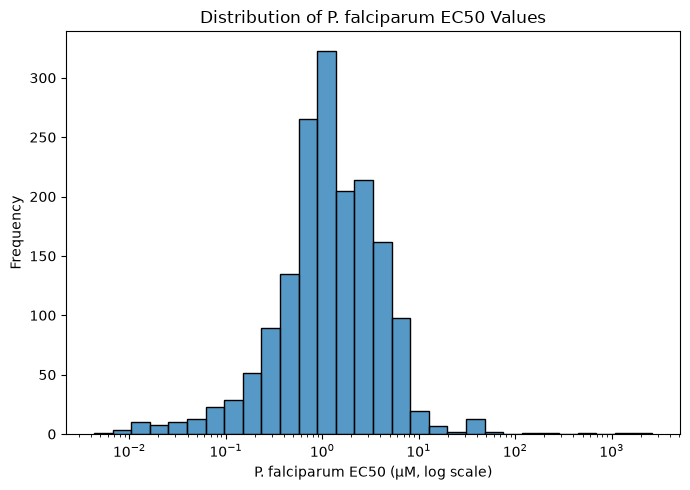

In [25]:
# Select valid EC50 values
ec50_data = mmv_chembl_df['pf_ec50_uM'].dropna()
ec50_data = ec50_data[ec50_data > 0]

plt.figure(figsize=(7, 5))

sns.histplot(
    x=ec50_data,
    bins=30,
    log_scale=True,
    edgecolor='black'
)

plt.xlabel('P. falciparum EC50 (µM, log scale)')
plt.ylabel('Frequency')
plt.title('Distribution of P. falciparum EC50 Values')

plt.tight_layout()
plt.show()

In [66]:
# Select Rule of Five violations and EC50
ro5_ec50_df = mmv_chembl_df[['ro5_violations', 'pf_ec50_uM']].copy()

# Remove rows missing either value
ro5_ec50_df = ro5_ec50_df.dropna()

# Keep positive EC50 values for the logarithmic scale
ro5_ec50_df = ro5_ec50_df[
    ro5_ec50_df['pf_ec50_uM'] > 0
]

print("Number of valid pairs:", len(ro5_ec50_df))

ro5_ec50_df.head()

Number of valid pairs: 1687


,ro5_violations,pf_ec50_uM
1,0.0,0.1630
2,0.0,0.7058
3,0.0,0.4143
4,0.0,2.4510
5,1.0,1.5084


In [68]:
import numpy as np

mmv_activity_df = mmv_chembl_df.copy()

ec50 = pd.to_numeric(mmv_activity_df['pf_ec50_uM'], errors='coerce')

mmv_activity_df['pEC50'] = 6 - np.log10(ec50.where(ec50 > 0))

mmv_activity_df[['pf_ec50_uM', 'pEC50']].head(10)

,pf_ec50_uM,pEC50
0,NaN,NaN
1,0.1630,6.787812
2,0.7058,6.151318
3,0.4143,6.382685
4,2.4510,5.610657
5,1.5084,5.821483
6,0.9974,6.001131
7,NaN,NaN
8,3.2033,5.494402
9,0.4227,6.373968


C:\Users\eghos\AppData\Local\Temp\ipykernel_45852\1939387204.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels)


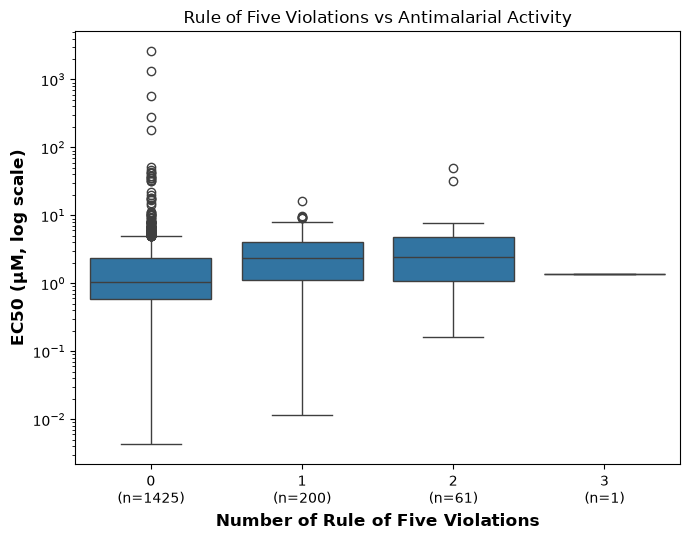

In [75]:
# Calculate the number of compounds in each group
group_counts = ro5_ec50_df.groupby('ro5_violations').size()

plt.figure(figsize=(7, 5.5))

ax = sns.boxplot(
    x='ro5_violations',
    y='pf_ec50_uM',
    data=ro5_ec50_df
)

plt.yscale('log')

# Add sample sizes to the X-axis labels
labels = [
    '0\n(n=1425)',
    '1\n(n=200)',
    '2\n(n=61)',
    '3\n(n=1)'
]

ax.set_xticklabels(labels)

plt.xlabel('Number of Rule of Five Violations', fontsize=12, fontweight='bold')
plt.ylabel('EC50 (µM, log scale)', fontsize=12, fontweight='bold')
plt.title('Rule of Five Violations vs Antimalarial Activity')

plt.tight_layout()
plt.show()

The box plot shows that compounds with zero Lipinski Rule of Five violations had the lowest median EC50 (1.06 µM), compared with compounds containing one (2.33 µM) or two violations (2.44 µM), suggesting greater antimalarial potency among the others. However, considerable variation and several outliers were observed, particularly in the zero-violation group, showing that meeting Lipinski's criteria does not necessarily guarantee high activity. Most compounds had zero violations (n = 1,425), while only one compound had three violations, making this group unsuitable for meaningful comparison.

In [65]:
from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    ro5_ec50_df['ro5_violations'],
    ro5_ec50_df['pf_ec50_uM']
)

print("Number of valid pairs:", len(ro5_ec50_df))
print("Spearman correlation:", round(correlation, 3))
print(f"P-value: {p_value:.3e}")

Number of valid pairs: 1687
Spearman correlation: 0.218
P-value: 1.347e-19


spearman correlation analysis showed a weak positive correlation between Lipinski Rule of Five violations and P. falciparum EC50 values (ρ = 0.218, p = 1.347 × 10⁻¹⁹). This indicates that compounds with more Rule of Five violations tend to have higher EC50 values and therefore lower antimalarial potency. The relationship was statistically significant, suggesting that the observed association is unlikely to be due to random variation alone. However, the correlation remains weak, indicating that Rule of Five violations alone cannot reliably predict antimalarial activi

In [28]:
# Select LogP and pEC50
logp_pec50_df = mmv_activity_df[['logp', 'pEC50']].copy()

# Remove rows missing either value
logp_pec50_df = logp_pec50_df.dropna()

print("Number of valid pairs:", len(logp_pec50_df))

logp_pec50_df.head()

Number of valid pairs: 1687


,logp,pEC50
1,2.42,6.787812
2,4.52,6.151318
3,2.71,6.382685
4,4.33,5.610657
5,3.60,5.821483


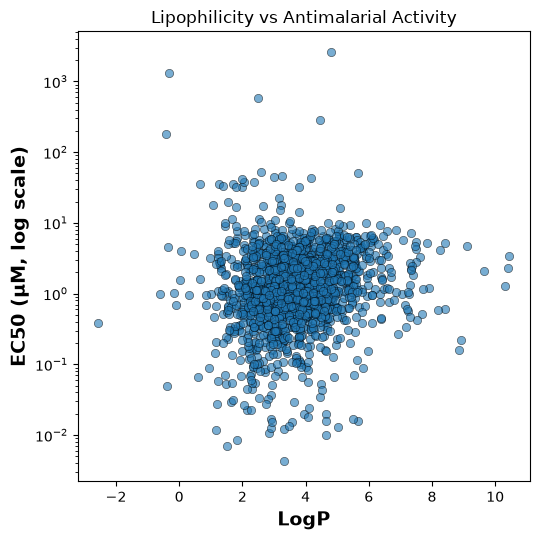

In [30]:
# Select LogP and EC50, removing incomplete pairs
logp_ec50_df = mmv_chembl_df[['logp', 'pf_ec50_uM']].dropna()

# Keep positive EC50 values
logp_ec50_df = logp_ec50_df[
    logp_ec50_df['pf_ec50_uM'] > 0
]

plt.figure(figsize=(5.5, 5.5))

sns.scatterplot(
    x='logp',
    y='pf_ec50_uM',
    data=logp_ec50_df,
    edgecolor='black',
    alpha=0.6
)

plt.yscale('log')

plt.xlabel('LogP', fontsize=14, fontweight='bold')
plt.ylabel('EC50 (µM, log scale)', fontsize=14, fontweight='bold')
plt.title('Lipophilicity vs Antimalarial Activity')

plt.tight_layout()
plt.show()

The scatter plot shows that most compounds have LogP values between approximately 2–6, with EC50 values mainly ranging from 0.1–10 µM. The points are widely spread, showing that compounds with similar LogP values can have very different antimalarial activities.

There appears to be a slight increase in EC50 as LogP increases, although the trend is not very clear. Several outliers are also present, with some compounds showing unusually high or low EC50 values compared with the majority.

Overall, the graph suggests that lipophilicity has a weak relationship with antimalarial activity. This indicates that LogP alone may not be enough to explain differences in potency, and other molecular properties are likely to play a role.

In [61]:
correlation, p_value = spearmanr(
    logp_ec50_df['logp'],
    logp_ec50_df['pf_ec50_uM']
)


print("P-value:", round(p_value, 4)) 
print(f"Spearman correlation: {correlation:.3f}")
print(f"P-value: {p_value:.3e}")

P-value: 0.0
Spearman correlation: 0.177
P-value: 2.604e-13


Spearman correlation analysis showed a weak positive relationship between LogP and EC50 (ρ = 0.177, p = 2.604 × 10⁻¹³). This suggests that compounds with higher LogP values tend to have slightly higher EC50 values, indicating lower antimalarial potency.

The p-value is below 0.05, meaning the relationship is statistically significant. However, the correlation value is close to zero, showing that the relationship is still weak.

Overall, these results support what was observed in the scatter plot, suggesting that lipophilicity may be associated with antimalarial activity but is unlikely to be a strong predictor of EC50 on its own.

In [37]:
# Select aromatic rings and EC50
aromatic_ec50_df = mmv_chembl_df[['aromatic_rings', 'pf_ec50_uM']].copy()

# Remove rows missing either value
aromatic_ec50_df = aromatic_ec50_df.dropna()

# Keep positive EC50 values for logarithmic scale
aromatic_ec50_df = aromatic_ec50_df[
    aromatic_ec50_df['pf_ec50_uM'] > 0
]

print("Number of valid pairs:", len(aromatic_ec50_df))

aromatic_ec50_df.head()

Number of valid pairs: 1687


,aromatic_rings,pf_ec50_uM
1,2.0,0.1630
2,3.0,0.7058
3,3.0,0.4143
4,3.0,2.4510
5,3.0,1.5084


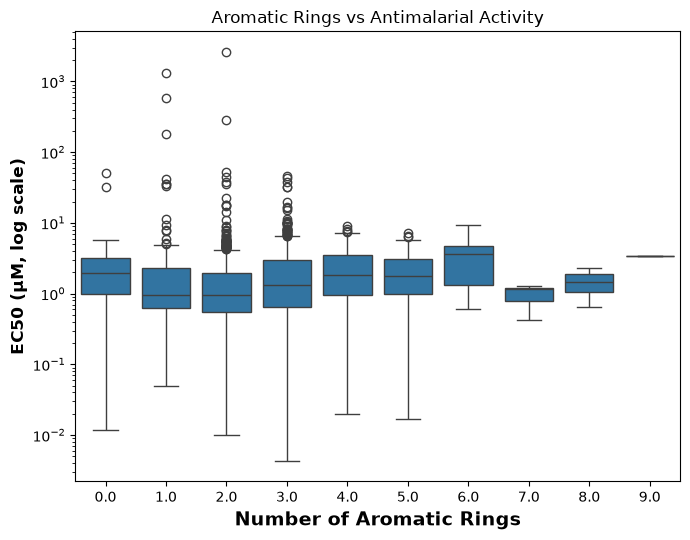

In [38]:
plt.figure(figsize=(7, 5.5))

sns.boxplot(
    x='aromatic_rings',
    y='pf_ec50_uM',
    data=aromatic_ec50_df
)

plt.yscale('log')

plt.xlabel('Number of Aromatic Rings', fontsize=14, fontweight='bold')
plt.ylabel('EC50 (µM, log scale)', fontsize=12, fontweight='bold')
plt.title('Aromatic Rings vs Antimalarial Activity')

plt.tight_layout()
plt.show()

The box plot shows how EC50 values vary between compounds with different numbers of aromatic rings. Compounds containing one or two aromatic rings generally have lower median EC50 values (approximately 1 µM), suggesting greater antimalarial potency compared with some of the other groups.

As the number of aromatic rings increases, the median EC50 tends to become higher, although this pattern is not consistent across all groups. There is also considerable overlap between the boxes, showing that compounds with different numbers of aromatic rings can have similar antimalarial activities.

In [62]:
from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    aromatic_ec50_df['aromatic_rings'],
    aromatic_ec50_df['pf_ec50_uM']
)

print("Aromatic Rings vs EC50")
print(f"Spearman correlation: {correlation:.3f}")
print(f"P-value: {p_value:.3e}")

Aromatic Rings vs EC50
Spearman correlation: 0.184
P-value: 2.468e-14



Spearman correlation analysis showed a weak positive relationship between aromatic ring count and EC50 (ρ = 0.184, p = 2.468 × 10⁻¹⁴). This suggests that compounds with more aromatic rings tend to have slightly higher EC50 values, indicating lower antimalarial potency.

The p-value is below 0.05, meaning the relationship is statistically significant. However, the correlation coefficient is relatively small, showing that the relationship is still weak.

Overall, these results support the general pattern observed in the box plot, suggesting that aromatic ring count may be associated with antimalarial activity but is unlikely to be a strong predictor of EC50 on its own.

In [50]:
# Select rotatable bonds and EC50
rtb_ec50_df = mmv_chembl_df[['rtb', 'pf_ec50_uM']].copy()

# Remove rows missing either value
rtb_ec50_df = rtb_ec50_df.dropna()

# Keep positive EC50 values for logarithmic scale
rtb_ec50_df = rtb_ec50_df[
    rtb_ec50_df['pf_ec50_uM'] > 0
]

print("Number of valid pairs:", len(rtb_ec50_df))

rtb_ec50_df.head()

Number of valid pairs: 1687


,rtb,pf_ec50_uM
1,3.0,0.1630
2,5.0,0.7058
3,4.0,0.4143
4,4.0,2.4510
5,18.0,1.5084


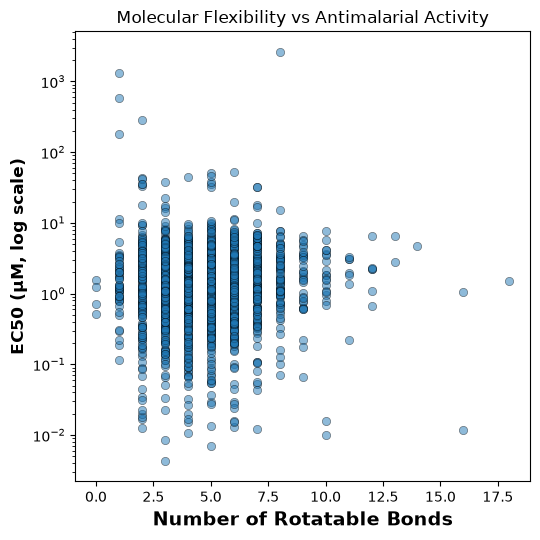

In [51]:
plt.figure(figsize=(5.5, 5.5))

sns.scatterplot(
    x='rtb',
    y='pf_ec50_uM',
    data=rtb_ec50_df,
    edgecolor='black',
    alpha=0.5
)

plt.yscale('log')

plt.xlabel('Number of Rotatable Bonds', fontsize=14, fontweight='bold')
plt.ylabel('EC50 (µM, log scale)', fontsize=12, fontweight='bold')
plt.title('Molecular Flexibility vs Antimalarial Activity')

plt.tight_layout()
plt.show()

e scatter plot shows that most compounds contain approximately 2–8 rotatable bonds, with fewer compounds having more than 10. EC50 values vary considerably within this range, showing that compounds with similar numbers of rotatable bonds can have very different antimalarial activities.

In [63]:
from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    rtb_ec50_df['rtb'],
    rtb_ec50_df['pf_ec50_uM']
)

print("Number of valid pairs:", len(rtb_ec50_df))
print(f"Spearman correlation: {correlation:.3f}")
print(f"P-value: {p_value:.3e}")

Number of valid pairs: 1687
Spearman correlation: 0.037
P-value: 1.306e-01


Spearman correlation analysis showed a very weak positive relationship between rotatable bond count and EC50 (ρ = 0.037, p = 0.1306). This indicates almost no consistent relationship between increasing molecular flexibility and antimalarial activity.

The p-value is greater than 0.05, meaning the relationship is not statistically significant. Therefore, there is insufficient evidence to suggest that the number of rotatable bonds is associated with changes in EC50.

Overall, these results support what was observed in the scatter plot, suggesting that rotatable bond count alone is unlikely to be a strong predictor of antimalarial activity.

In [53]:
# Select PSA and EC50
psa_ec50_df = mmv_chembl_df[['psa', 'pf_ec50_uM']].copy()

# Remove rows missing either value
psa_ec50_df = psa_ec50_df.dropna()

# Keep positive EC50 values for logarithmic scale
psa_ec50_df = psa_ec50_df[
    psa_ec50_df['pf_ec50_uM'] > 0
]

print("Number of valid pairs:", len(psa_ec50_df))

psa_ec50_df.head()

Number of valid pairs: 1687


,psa,pf_ec50_uM
1,43.38,0.1630
2,38.56,0.7058
3,126.73,0.4143
4,46.61,2.4510
5,90.34,1.5084


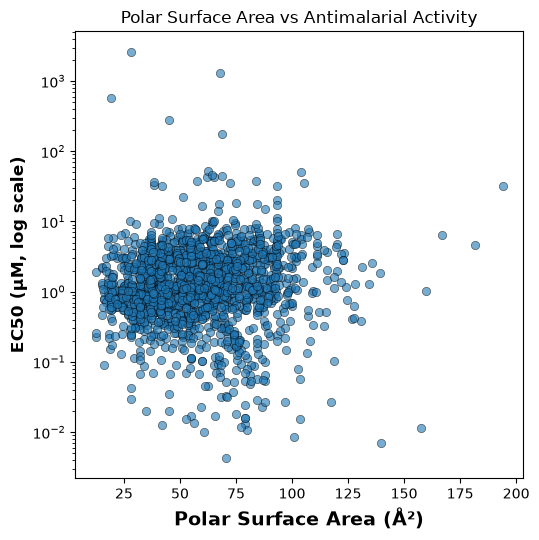

In [54]:
plt.figure(figsize=(5.5, 5.5))

sns.scatterplot(
    x='psa',
    y='pf_ec50_uM',
    data=psa_ec50_df,
    edgecolor='black',
    alpha=0.6
)

plt.yscale('log')

plt.xlabel('Polar Surface Area (Å²)', fontsize=14, fontweight='bold')
plt.ylabel('EC50 (µM, log scale)', fontsize=12, fontweight='bold')
plt.title('Polar Surface Area vs Antimalarial Activity')

plt.tight_layout()
plt.show()

The scatter plot shows that most compounds have polar surface areas between approximately 20–100 Å², with EC50 values mainly ranging from 0.1–10 µM. The points are widely spread, showing that compounds with similar PSA values can have very different antimalarial activities.

There appears to be a slight increase in EC50 as PSA increases, although the trend is not very clear. Several outliers are also present, including compounds with EC50 values exceeding 1,000 µM and others with very low EC50 values

In [64]:
from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    psa_ec50_df['psa'],
    psa_ec50_df['pf_ec50_uM']
)

print("Number of valid pairs:", len(psa_ec50_df))
print(f"Spearman correlation: {correlation:.3f}")
print(f"P-value: {p_value:.3e}")

Number of valid pairs: 1687
Spearman correlation: 0.127
P-value: 1.739e-07


Spearman correlation analysis showed a weak positive relationship between polar surface area (PSA) and EC50 (ρ = 0.127, p = 1.739 × 10⁻⁷). This suggests that compounds with higher PSA values tend to have slightly higher EC50 values, indicating lower antimalarial potency.

The p-value is below 0.05, meaning the relationship is statistically significant. However, the correlation coefficient is relatively small, showing that the relationship is still weak.

Overall, these results reaffirm the slight upward trend observed in the scatter plot. Although PSA may be associated with antimalarial activity, it is unlikely to be a strong predictor of EC50 on its own

In [56]:
# Select molecular properties and EC50
properties = [
    'logp',
    'psa',
    'rtb',
    'aromatic_rings',
    'ro5_violations',
    'pf_ec50_uM'
]

mmv_correlation_df = mmv_chembl_df[properties].copy()

# Exclude non-positive EC50 values
mmv_correlation_df.loc[
    mmv_correlation_df['pf_ec50_uM'] <= 0,
    'pf_ec50_uM'
] = float('nan')

mmv_correlation_df.head()

,logp,psa,rtb,aromatic_rings,ro5_violations,pf_ec50_uM
0,2.01,67.07,3.0,2.0,0.0,NaN
1,2.42,43.38,3.0,2.0,0.0,0.1630
2,4.52,38.56,5.0,3.0,0.0,0.7058
3,2.71,126.73,4.0,3.0,0.0,0.4143
4,4.33,46.61,4.0,3.0,0.0,2.4510


In [57]:
# Calculate Spearman correlation matrix
correlation_matrix = mmv_correlation_df.corr(method='spearman')

correlation_matrix

,logp,psa,rtb,aromatic_rings,ro5_violations,pf_ec50_uM
logp,1.000000,-0.275136,0.241055,0.462506,0.518482,0.176786
psa,-0.275136,1.000000,0.100073,0.285791,0.071197,0.126800
rtb,0.241055,0.100073,1.000000,0.064378,0.212502,0.036819
aromatic_rings,0.462506,0.285791,0.064378,1.000000,0.338428,0.184156
ro5_violations,0.518482,0.071197,0.212502,0.338428,1.000000,0.218002
pf_ec50_uM,0.176786,0.126800,0.036819,0.184156,0.218002,1.000000


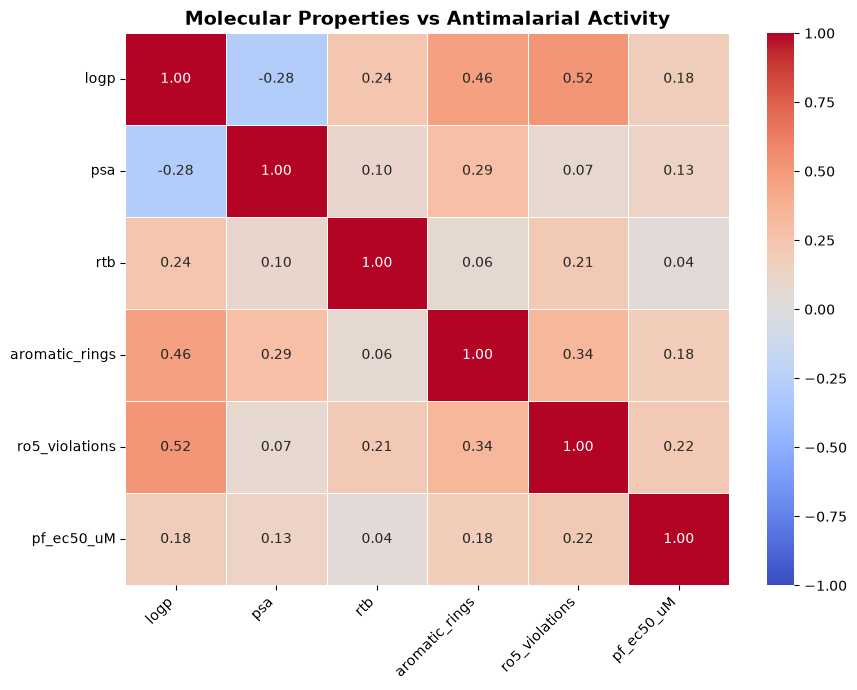

In [58]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Molecular Properties vs Antimalarial Activity',
          fontsize=14, fontweight='bold')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

The heatmap shows how the five molecular properties relate to each other and to P. falciparum EC50 values. Overall, all five properties show weak positive correlations with EC50, suggesting that none of them has a strong relationship with antimalarial activity on its own.

Rule of Five violations showed the strongest relationship with EC50 (ρ = 0.218), followed by aromatic rings (ρ = 0.184), LogP (ρ = 0.177) and PSA (ρ = 0.127). Rotatable bonds showed the weakest relationship (ρ = 0.037).

The heatmap also shows that some molecular properties are related to each other. For example, LogP and Rule of Five violations have a moderate positive correlation (ρ = 0.518), meaning that compounds with higher lipophilicity tend to have more violations. LogP and aromatic rings also show a positive correlation (ρ = 0.463), while LogP and PSA show a weak negative correlation (ρ = −0.275).

Overall, the results suggest that some molecular properties are connected, but none has a strong individual relationship with EC50. 